In [1]:
# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
# ============================================================
# STEP 2: LOAD DATASETS
# ============================================================

sales_df = pd.read_excel("Pizza_Sale.xlsx")

pizza_df = pd.read_excel("Pizza_ingredients.xlsx")

ingredients_df = pd.read_csv("ingredients_data.csv")

display(sales_df.head())
display(pizza_df.head())
display(ingredients_df.head())

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01 00:00:00,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01 00:00:00,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01 00:00:00,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01 00:00:00,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


,pizza_name_id,pizza_name,pizza_ingredients,Items_Qty_In_Grams
0,bbq_ckn_l,The Barbecue Chicken Pizza,Barbecued Chicken,40.0
1,bbq_ckn_l,The Barbecue Chicken Pizza,Red Peppers,15.0
2,bbq_ckn_l,The Barbecue Chicken Pizza,Green Peppers,20.0
3,bbq_ckn_l,The Barbecue Chicken Pizza,Tomatoes,30.0
4,bbq_ckn_l,The Barbecue Chicken Pizza,Red Onions,60.0


,pizza_name_id,pizza_ingredients,Items_Qty_In_Grams
0,hawaiian_m,Dough,200
1,hawaiian_m,Pizza Sauce,80
2,hawaiian_m,Mozzarella Cheese,100
3,hawaiian_m,Ham,50
4,hawaiian_m,Pineapple,60


In [3]:
# ============================================================
# STEP 3: INSPECT DATA
# ============================================================

sales_df.info()
pizza_df.info()
ingredients_df.info()

print("Sales:", sales_df.shape)
print("Pizza:", pizza_df.shape)
print("Ingredients:", ingredients_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48604 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48613 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48597 non-null  object 
 10  pizza_ingredients  48607 non-null  object 
 11  pizza_name         48613 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 518 entries, 0 to 517
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
--- 

In [4]:
# ============================================================
# STEP 4: DATA CLEANING
# ============================================================

# Remove duplicate rows
sales_df.drop_duplicates(inplace=True)
pizza_df.drop_duplicates(inplace=True)
ingredients_df.drop_duplicates(inplace=True)

# Remove rows with missing values
sales_df.dropna(inplace=True)
pizza_df.dropna(inplace=True)
ingredients_df.dropna(inplace=True)

# Remove extra spaces from column names
sales_df.columns = sales_df.columns.str.strip()
pizza_df.columns = pizza_df.columns.str.strip()
ingredients_df.columns = ingredients_df.columns.str.strip()

In [5]:
# ============================================================
# STEP 5: COMBINE DATASETS
# ============================================================

# Merge Sales Dataset with Pizza Details Dataset
combined_df = pd.merge(
    sales_df,
    pizza_df,
    on="pizza_name_id",
    how="left"
)

# Merge with Ingredients Dataset
combined_df = pd.merge(
    combined_df,
    ingredients_df,
    on="pizza_name_id",
    how="left"
)

display(combined_df.head())

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients_x,pizza_name_x,pizza_name_y,pizza_ingredients_y,Items_Qty_In_Grams_x,pizza_ingredients,Items_Qty_In_Grams_y
0,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,The Hawaiian Pizza,Pineapple,30.0,Dough,200.0
1,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,The Hawaiian Pizza,Pineapple,30.0,Pizza Sauce,80.0
2,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,The Hawaiian Pizza,Pineapple,30.0,Mozzarella Cheese,100.0
3,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,The Hawaiian Pizza,Pineapple,30.0,Ham,50.0
4,1,1,hawaiian_m,1,2015-01-01 00:00:00,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,The Hawaiian Pizza,Pineapple,30.0,Pineapple,60.0


,pizza_id,order_id,quantity,unit_price,total_price,Items_Qty_In_Grams_x,Items_Qty_In_Grams_y
count,299816.000000,299816.000000,299816.000000,299816.000000,299816.000000,299816.000000,43446.000000
mean,24334.338294,10711.822394,1.018405,16.790413,17.102564,33.937782,95.250541
std,14016.273857,6171.596410,0.138178,3.489626,4.292979,32.312267,75.461895
min,1.000000,1.000000,1.000000,9.750000,9.750000,5.000000,20.000000
25%,12240.000000,5374.000000,1.000000,12.750000,12.750000,15.000000,30.000000
50%,24269.000000,10663.000000,1.000000,16.500000,16.500000,20.000000,80.000000
75%,36487.000000,16109.000000,1.000000,20.500000,20.500000,40.000000,120.000000
max,48620.000000,21350.000000,4.000000,35.950000,83.000000,200.000000,300.000000


,quantity
pizza_name_id,
four_cheese_m,17520
classic_dlx_l,14190
five_cheese_l,8424
southw_ckn_l,8112
big_meat_s,7652
pepperoni_m,7504
thai_ckn_l,7040
mexicana_l,6912
spicy_ital_l,6642


<Axes: >

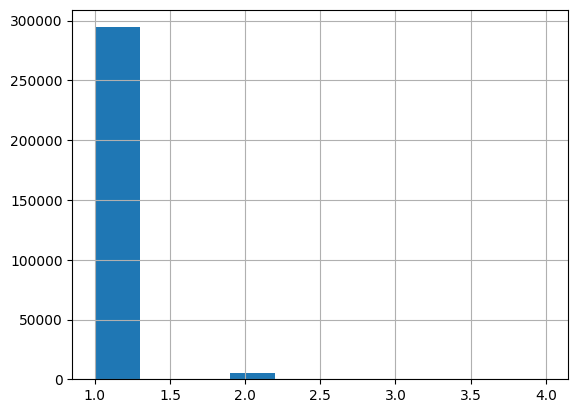

In [6]:
# ============================================================
# STEP 6: EXPLORATORY DATA ANALYSIS
# ============================================================

# Basic statistical summary
display(combined_df.describe())

# Check sales by pizza
pizza_sales = combined_df.groupby("pizza_name_id")["quantity"].sum().sort_values(ascending=False)

display(pizza_sales.head(10))

# Sales distribution
combined_df["quantity"].hist()

In [7]:
# ============================================================
# STEP 7: FEATURE ENGINEERING
# ============================================================

# Convert order date to datetime
combined_df["order_date"] = pd.to_datetime(combined_df["order_date"])

# Create date-based features
combined_df["year"] = combined_df["order_date"].dt.year
combined_df["month"] = combined_df["order_date"].dt.month
combined_df["day"] = combined_df["order_date"].dt.day
combined_df["day_of_week"] = combined_df["order_date"].dt.dayofweek

# Create total sales amount
combined_df["total_sales"] = (
    combined_df["quantity"] * combined_df["unit_price"]
)

# Create demand category
combined_df["demand_category"] = pd.cut(
    combined_df["quantity"],
    bins=[-1, 2, 5, float("inf")],
    labels=["Low", "Medium", "High"]
)

display(combined_df.head())

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,...,pizza_ingredients_y,Items_Qty_In_Grams_x,pizza_ingredients,Items_Qty_In_Grams_y,year,month,day,day_of_week,total_sales,demand_category
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,...,Pineapple,30.0,Dough,200.0,2015,1,1,3,13.25,Low
1,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,...,Pineapple,30.0,Pizza Sauce,80.0,2015,1,1,3,13.25,Low
2,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,...,Pineapple,30.0,Mozzarella Cheese,100.0,2015,1,1,3,13.25,Low
3,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,...,Pineapple,30.0,Ham,50.0,2015,1,1,3,13.25,Low
4,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,...,Pineapple,30.0,Pineapple,60.0,2015,1,1,3,13.25,Low


In [8]:
# ============================================================
# STEP 8: LINEAR REGRESSION
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select features and target
X = combined_df[["unit_price", "month", "day_of_week"]]
y = combined_df["quantity"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict
lr_pred = lr_model.predict(X_test)

# Evaluation
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression R²:", lr_r2)

Linear Regression R²: 4.341924034556577e-05


In [9]:
# ============================================================
# STEP 9: RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestRegressor

# Train model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Evaluation
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest R²:", rf_r2)

Random Forest R²: 0.028384422894304095


In [10]:
# ============================================================
# STEP 10: NAIVE BAYES
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Select features and target
X_class = combined_df[["unit_price", "month", "day_of_week"]]
y_class = combined_df["demand_category"]

# Remove missing values
class_data = pd.concat([X_class, y_class], axis=1).dropna()

X_class = class_data[["unit_price", "month", "day_of_week"]]
y_class = class_data["demand_category"]

# Split data
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42
)

# Train Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train_class, y_train_class)

# Predict
nb_pred = nb_model.predict(X_test_class)

# Evaluation
nb_accuracy = accuracy_score(y_test_class, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy)

Naive Bayes Accuracy: 0.9995330531652324


In [11]:
# ============================================================
# STEP 11: DEMAND PREDICTION
# ============================================================

# Example future demand input
new_data = pd.DataFrame({
    "unit_price": [15.0],
    "month": [12],
    "day_of_week": [4]
})

# Predict demand
predicted_demand = rf_model.predict(new_data)

print("Predicted Pizza Demand:", round(predicted_demand[0], 2))

Predicted Pizza Demand: 1.0


In [12]:
# ============================================================
# STEP 12: INGREDIENT CALCULATION
# ============================================================

predicted_quantity = round(predicted_demand[0])

ingredient_requirement = ingredients_df.copy()

ingredient_requirement["Required_Quantity_Grams"] = (
    ingredient_requirement["Items_Qty_In_Grams"] * predicted_quantity
)

display(ingredient_requirement.head())

,pizza_name_id,pizza_ingredients,Items_Qty_In_Grams,Required_Quantity_Grams
0,hawaiian_m,Dough,200,200
1,hawaiian_m,Pizza Sauce,80,80
2,hawaiian_m,Mozzarella Cheese,100,100
3,hawaiian_m,Ham,50,50
4,hawaiian_m,Pineapple,60,60


In [13]:
# ============================================================
# STEP 13: PURCHASE REQUIREMENT
# ============================================================

purchase_requirement = ingredient_requirement.copy()

# Convert grams to kilograms
purchase_requirement["Required_Quantity_Kg"] = (
    purchase_requirement["Required_Quantity_Grams"] / 1000
)

# Keep required columns
purchase_requirement = purchase_requirement[
    [
        "pizza_name_id",
        "pizza_ingredients",
        "Required_Quantity_Grams",
        "Required_Quantity_Kg"
    ]
]

display(purchase_requirement)

,pizza_name_id,pizza_ingredients,Required_Quantity_Grams,Required_Quantity_Kg
0,hawaiian_m,Dough,200,0.200
1,hawaiian_m,Pizza Sauce,80,0.080
2,hawaiian_m,Mozzarella Cheese,100,0.100
3,hawaiian_m,Ham,50,0.050
4,hawaiian_m,Pineapple,60,0.060
5,classic_dlx_l,Dough,300,0.300
6,classic_dlx_l,Pizza Sauce,120,0.120
7,classic_dlx_l,Mozzarella Cheese,150,0.150
8,classic_dlx_l,Pepperoni,40,0.040
9,classic_dlx_l,Mushrooms,30,0.030


In [14]:
# ============================================================
# STEP 14: FINAL ANALYSIS
# ============================================================

model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Naive Bayes"
    ],
    "Metric": [
        "R² Score",
        "R² Score",
        "Accuracy"
    ],
    "Score": [
        lr_r2,
        rf_r2,
        nb_accuracy
    ]
})

display(model_results)

print("Predicted Demand:", predicted_quantity)

display(
    purchase_requirement[
        [
            "pizza_name_id",
            "pizza_ingredients",
            "Required_Quantity_Grams",
            "Required_Quantity_Kg"
        ]
    ]
)

,Model,Metric,Score
0,Linear Regression,R² Score,0.000043
1,Random Forest,R² Score,0.028384
2,Naive Bayes,Accuracy,0.999533


Predicted Demand: 1


,pizza_name_id,pizza_ingredients,Required_Quantity_Grams,Required_Quantity_Kg
0,hawaiian_m,Dough,200,0.200
1,hawaiian_m,Pizza Sauce,80,0.080
2,hawaiian_m,Mozzarella Cheese,100,0.100
3,hawaiian_m,Ham,50,0.050
4,hawaiian_m,Pineapple,60,0.060
5,classic_dlx_l,Dough,300,0.300
6,classic_dlx_l,Pizza Sauce,120,0.120
7,classic_dlx_l,Mozzarella Cheese,150,0.150
8,classic_dlx_l,Pepperoni,40,0.040
9,classic_dlx_l,Mushrooms,30,0.030


In [15]:
# ============================================================
# USER INPUT: DEMAND PREDICTION
# ============================================================

user_date = input("Enter the date (YYYY-MM-DD): ")

date = pd.to_datetime(user_date)

user_input = pd.DataFrame({
    "unit_price": [combined_df["unit_price"].mean()],
    "month": [date.month],
    "day_of_week": [date.dayofweek]
})

predicted_demand = rf_model.predict(user_input)

print("Predicted Pizza Demand:", round(predicted_demand[0]))

Enter the date (YYYY-MM-DD): 2026-10-29
Predicted Pizza Demand: 1
